In [ ]:
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm as tq

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

In [ ]:
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Rescaling
from tensorflow.keras.layers import RandomRotation, RandomTranslation, RandomZoom, RandomFlip
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau

In [ ]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
# Setingan Manual Model
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 123
RANDOM_STATE = 42

In [ ]:
from google.colab import files
files.view("/content/drive/MyDrive/DEEP_LEARNING/kaggle.json")

<IPython.core.display.Javascript object>

In [ ]:
!kaggle datasets download -d maimunulkjisan/rice-leaf-dataset-from-mendeley-data
!unzip rice-leaf-dataset-from-mendeley-data.zip

Streaming output truncated to the last 5000 lines.
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_141.JPG  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_142.JPG  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_143.JPG  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_144.JPG  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_145.JPG  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_146.JPG  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_147.jpg  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_148.jpg  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_149.jpg  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_150.jpg  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACTERIALBLIGHT1_151.jpg  
  inflating: Rice Leaf Disease Images/Bacterialblight/BACT

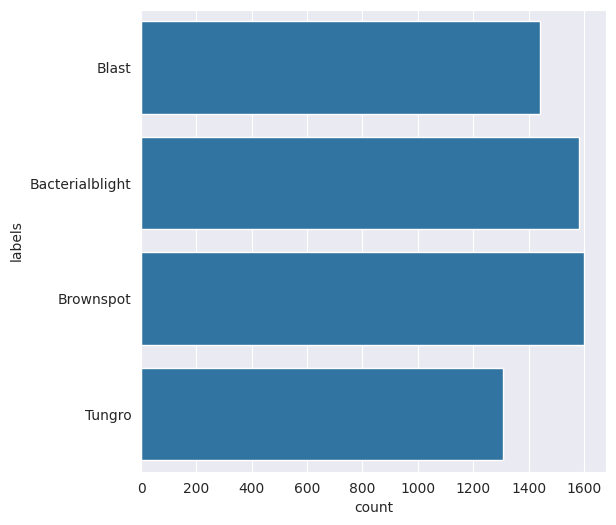

In [ ]:
lung_path = "Rice Leaf Disease Images"

file_name = []
labels = []
full_path = []

for path, subdirs, files in os.walk(lung_path):
    for name in files:
        full_path.append(os.path.join(path, name))
        labels.append(path.split('/')[-1])
        file_name.append(name)

distribution_image = pd.DataFrame({"path":full_path, 'file_name':file_name, "labels":labels})

Label = distribution_image['labels']
plt.figure(figsize = (6,6))
sns.set_style("darkgrid")
plot_data = sns.countplot(Label)

In [ ]:
for distribusion in distribution_image['labels'].unique():
  print(f"Total {distribusion} : {distribution_image[distribution_image['labels'] == distribusion].count()['labels']}")

print("===================================================")
print(f"Total Dataset Image Keseluruhan : {Label.count()}")

Total Blast : 1440
Total Bacterialblight : 1584
Total Brownspot : 1600
Total Tungro : 1308
Total Dataset Image Keseluruhan : 5932


In [ ]:
df = distribution_image.copy()
df.head()

,path,file_name,labels
0,Rice Leaf Disease Images/Blast/BLAST9_027.jpg,BLAST9_027.jpg,Blast
1,Rice Leaf Disease Images/Blast/BLAST6_135.JPG,BLAST6_135.JPG,Blast
2,Rice Leaf Disease Images/Blast/BLAST9_030.jpg,BLAST9_030.jpg,Blast
3,Rice Leaf Disease Images/Blast/BLAST4_038.jpg,BLAST4_038.jpg,Blast
4,Rice Leaf Disease Images/Blast/BLAST8_064.JPG,BLAST8_064.JPG,Blast


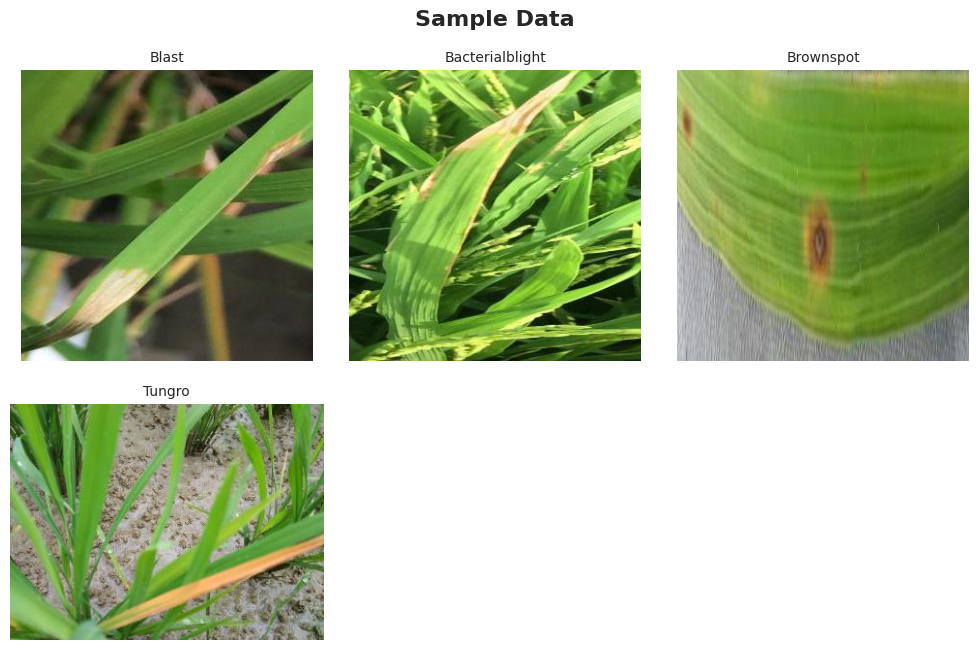

In [ ]:
unique_labels = df['labels'].unique()

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
fig.suptitle("Sample Data", fontsize=16, fontweight='bold')

axes = axes.flatten()

# Looping untuk menampilkan gambar sesuai jumlah unique_labels
for i, uniq in enumerate(unique_labels):
    sample_path = df[df['labels'] == uniq]['path'].values[0]

    img = Image.open(sample_path)

    axes[i].imshow(img)
    axes[i].set_title(uniq, fontsize=10)
    axes[i].axis('off')

# Menyembunyikan sisa subplot yang kosong
for j in range(len(unique_labels), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

In [ ]:
X= df['path']
y= df['labels']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, shuffle=True, stratify=y)

In [ ]:
df_tr = pd.DataFrame({'path':X_train,'labels':y_train,'set':'train'})
df_te = pd.DataFrame({'path':X_test,'labels':y_test,'set':'test'})
df_all = pd.concat([df_tr, df_te], ignore_index=True)

print('===================================================== \n')
print(df_all.groupby(['set', 'labels']).size(), '\n')
print('===================================================== \n')

print(df_all.sample(5))


set    labels         
test   Bacterialblight     317
       Blast               288
       Brownspot           320
       Tungro              262
train  Bacterialblight    1267
       Blast              1152
       Brownspot          1280
       Tungro             1046
dtype: int64 


                                                   path           labels  \
2266  Rice Leaf Disease Images/Bacterialblight/BACTE...  Bacterialblight   
5744      Rice Leaf Disease Images/Blast/BLAST1_136.JPG            Blast   
2733      Rice Leaf Disease Images/Blast/BLAST6_060.JPG            Blast   
4323  Rice Leaf Disease Images/Bacterialblight/BACTE...  Bacterialblight   
4410  Rice Leaf Disease Images/Bacterialblight/BACTE...  Bacterialblight   

        set  
2266  train  
5744   test  
2733  train  
4323  train  
4410  train  


In [ ]:
df_all.head()

,path,labels,set
0,Rice Leaf Disease Images/Bacterialblight/BACTE...,Bacterialblight,train
1,Rice Leaf Disease Images/Tungro/TUNGRO1_118.JPG,Tungro,train
2,Rice Leaf Disease Images/Bacterialblight/BACTE...,Bacterialblight,train
3,Rice Leaf Disease Images/Bacterialblight/BACTE...,Bacterialblight,train
4,Rice Leaf Disease Images/Tungro/TUNGRO2_168.JPG,Tungro,train


In [ ]:
datasource_path = lung_path
dataset_path = "new_dataset/"

for index, row in tq(df_all.iterrows()):
    file_path = row['path']
    if os.path.exists(file_path) == False:
            file_path = os.path.join(datasource_path,row['labels'],row['image'].split('.')[0])

    if os.path.exists(os.path.join(dataset_path,row['set'],row['labels'])) == False:
        os.makedirs(os.path.join(dataset_path,row['set'],row['labels']))

    destination_file_name = file_path.split('/')[-1]
    file_dest = os.path.join(dataset_path,row['set'],row['labels'],destination_file_name)

    if os.path.exists(file_dest) == False:
        shutil.copy2(file_path,file_dest)

0it [00:00, ?it/s]

In [ ]:
TRAIN_DIR = "new_dataset/train/"
TEST_DIR = "new_dataset/test/"
arr_train = []
arr_test = []

for key, data in enumerate(os.listdir(TRAIN_DIR)):
  dict_train = {"train_name" : f"train_{data}",
                "train_path" : os.path.join(f"{TRAIN_DIR}{data}")}
  arr_train.append(dict_train)
for key, data in enumerate(os.listdir(TEST_DIR)):
  dict_test = {"test_name" : f"test_{data}",
                "test_path" : os.path.join(f"{TEST_DIR}{data}")}
  arr_test.append(dict_test)

for ar_tr in arr_train:
  print(f"Total number of {ar_tr["train_name"].replace("_", " ")} : {len(os.listdir(ar_tr["train_path"]))}")

print("===================================================")

for ar_ts in arr_test:
  print(f"Total number of {ar_ts["test_name"].replace("_", " ")} : {len(os.listdir(ar_ts["test_path"]))}")

Total number of train Blast : 1152
Total number of train Bacterialblight : 1267
Total number of train Brownspot : 1280
Total number of train Tungro : 1046
Total number of test Blast : 288
Total number of test Bacterialblight : 317
Total number of test Brownspot : 320
Total number of test Tungro : 262


In [ ]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical'
)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical'
)
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False
)
class_names = test_dataset.class_names
NUM_CLASSES = len(train_dataset.class_names)
print(f"Jumlah kelas terdeteksi: {NUM_CLASSES}")

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Found 4745 files belonging to 4 classes.
Using 3796 files for training.
Found 4745 files belonging to 4 classes.
Using 949 files for validation.
Found 1187 files belonging to 4 classes.
Jumlah kelas terdeteksi: 4


In [ ]:
data_augmentation = Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.2),
    RandomTranslation(height_factor=0.2, width_factor=0.2),
    RandomZoom(0.2),
], name="augmentation_layer")

# LAYER BARU KHUSUS MOBILENETV2 (Rumus: (x / 127.5) - 1 )
# Ini mengubah rentang 0-255 menjadi -1 sampai 1
mobilenet_preprocess = Rescaling(scale=1./127.5, offset=-1, name="mobilenet_rescale")

# Muat Base Model MobileNetV2
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

# Rangkai Model
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = mobilenet_preprocess(x)         # <--- Masukkan layer rescale di sini!
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_layer (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_rescale (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# 1. Buat Custom Callback
class StopAtThreshold(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        # Mengecek apakah akurasi validasi sudah 96% (0.96) atau lebih
        if logs.get('val_accuracy') >= 0.96:
            print("\nTarget akurasi validasi 96% tercapai! Menghentikan training...")
            self.model.stop_training = True

# 2. Inisialisasi Custom Callback
stop_threshold = StopAtThreshold()

# 3. Gabungkan ke dalam callbacks_list
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(filepath='model_padi_mobilenetv2.keras', monitor='val_accuracy', save_best_only=True),
    stop_threshold  # <--- Custom callback ditambahkan di sini
]

In [ ]:
print("\n--- MULAI TAHAP 1: FEATURE EXTRACTION ---")
history_1 = model.fit(train_dataset, validation_data=val_dataset, epochs=15, callbacks=callbacks_list)


--- MULAI TAHAP 1: FEATURE EXTRACTION ---
Epoch 1/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 24s 82ms/step - accuracy: 0.6981 - loss: 0.7539 - val_accuracy: 0.8535 - val_loss: 0.3621 - learning_rate: 0.0010
Epoch 2/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 8s 68ms/step - accuracy: 0.8562 - loss: 0.3840 - val_accuracy: 0.8999 - val_loss: 0.2710 - learning_rate: 0.0010
Epoch 3/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step - accuracy: 0.8880 - loss: 0.3061 - val_accuracy: 0.9083 - val_loss: 0.2419 - learning_rate: 0.0010
Epoch 4/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.8938 - loss: 0.2787 - val_accuracy: 0.9020 - val_loss: 0.2375 - learning_rate: 0.0010
Epoch 5/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 8s 68ms/step - accuracy: 0.9033 - loss: 0.2517 - val_accuracy: 0.9252 - val_loss: 0.2079 - learning_rate: 0.0010
Epoch 6/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 8s 68ms/step - accuracy: 0.9191 - loss: 0.2264 - val_accuracy: 0.9378 - val_loss: 0.1854 - learning_rate: 0.0010
Epoch 7/15
119/119 ━━━━━━━━━━━━━━━━━━━

In [ ]:
print("Sedang mengevaluasi model pada Data Test...")
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"--------------------------------------------------")
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"TEST LOSS:     {test_loss:.4f}")
print(f"--------------------------------------------------")

Sedang mengevaluasi model pada Data Test...
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.9377 - loss: 0.1670
--------------------------------------------------
TEST ACCURACY: 0.9377 (93.77%)
TEST LOSS:     0.1670
--------------------------------------------------


In [ ]:
print("Melakukan prediksi...")
# 1. Prediksi langsung dengan memanggil dataset (tidak perlu reset atau steps)
predictions = model.predict(test_dataset)

# 2. Ubah probabilitas menjadi index kelas tertinggi
predicted_classes = np.argmax(predictions, axis=1)

# 3. Ekstrak label asli (true labels) langsung dari test_dataset
# Karena kita menggunakan label_mode='categorical', label berbentuk one-hot (misal: [0, 1, 0])
true_labels_onehot = np.concatenate([y for x, y in test_dataset], axis=0)
true_classes = np.argmax(true_labels_onehot, axis=1)

# 4. Ambil nama kelas (menggunakan variabel class_names yang sudah kita definisikan saat training)
# Jika variabel class_names hilang di cell/notebook, Anda bisa memanggilnya lagi lewat test_dataset aslinya
# class_names = ['healthy', 'bacterial_spot', ...]

print("\nCLASSIFICATION REPORT:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

Melakukan prediksi...
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step

CLASSIFICATION REPORT:
                 precision    recall  f1-score   support

Bacterialblight       0.89      0.94      0.92       317
          Blast       0.92      0.85      0.88       288
      Brownspot       0.95      0.96      0.95       320
         Tungro       1.00      1.00      1.00       262

       accuracy                           0.94      1187
      macro avg       0.94      0.94      0.94      1187
   weighted avg       0.94      0.94      0.94      1187



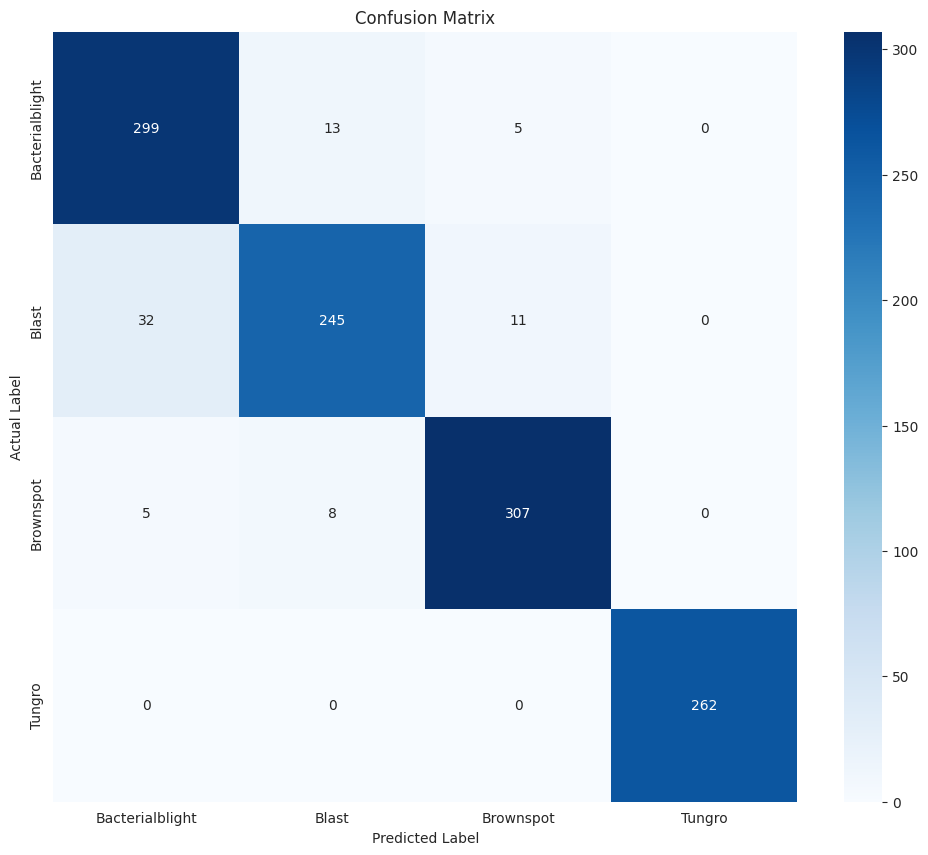

In [ ]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

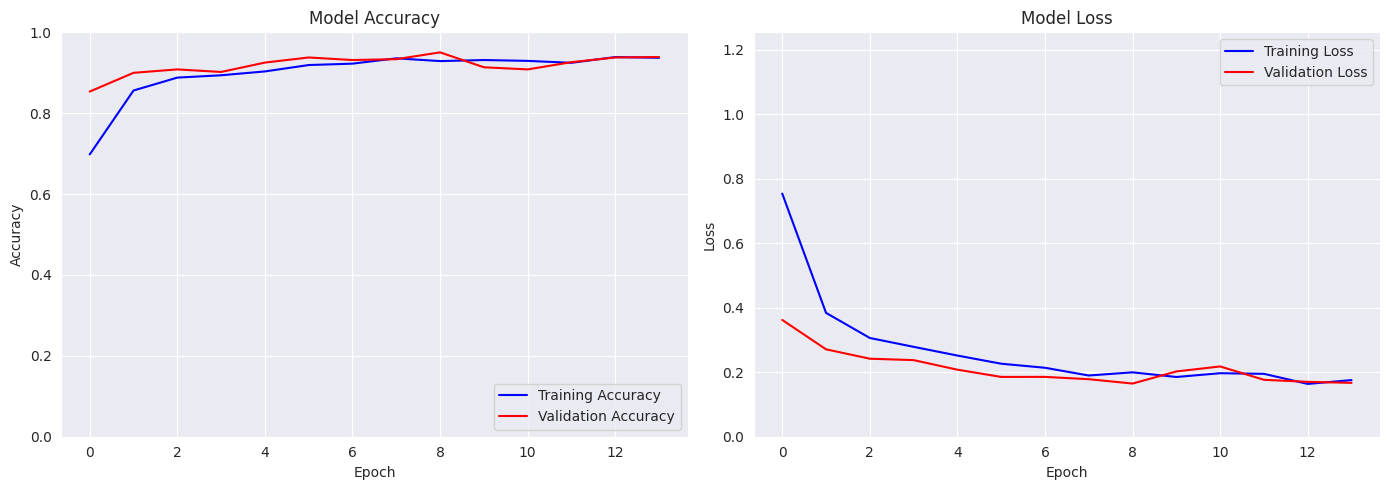

In [ ]:
if 'history_1' in locals():
    acc = history_1.history['accuracy']
    val_acc = history_1.history['val_accuracy']
    loss = history_1.history['loss']
    val_loss = history_1.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim([0, 1])

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.ylim([0, max(loss)+0.5])

    plt.tight_layout()
    plt.show()
else:
    print("Variabel 'history' tidak ditemukan. Pastikan Anda menyimpan output model.fit ke variabel 'history'.")

In [ ]:
shutil.copy("/content/model_padi_mobilenetv2.keras", "/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Model/Rice_MobileNetV2_pre-trained.keras")

'/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Model/Rice_MobileNetV2_pre-trained.keras'

In [ ]:
def predict_image(img_path, model, class_names):
    # 1. Muat gambar dan pastikan ukurannya sesuai dengan input model
    img = image.load_img(img_path, target_size=(224, 224))

    # 2. Ubah gambar menjadi array
    img_array = image.img_to_array(img)

    # 3. Tambahkan dimensi batch (dari (224, 224, 3) menjadi (1, 224, 224, 3))
    img_array = np.expand_dims(img_array, axis=0)

    # CATATAN: Rescale (img_array /= 255.0) sengaja ditiadakan untuk EfficientNet

    # 4. Lakukan prediksi
    predictions = model.predict(img_array)

    # 5. Ekstrak hasil
    predicted_class = np.argmax(predictions[0])
    confidence = np.max(predictions[0])

    print(f'Predicted: {class_names[predicted_class]} (Confidence: {confidence:.2%})')

    # Opsional: Kembalikan nilai jika ingin digunakan di variabel lain
    return class_names[predicted_class], confidence

predict_image('/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Sample/3c4f2de5549f80.webp', model, class_names)
predict_image('/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Sample/brownspot.jpg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Sample/brown-spot-disease-rice-caused-260nw-2570506623.webp', model, class_names)
predict_image('/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Sample/penyakit-hawar-daun-bakteri.jpg', model, class_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted: Tungro (Confidence: 99.66%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Predicted: Brownspot (Confidence: 98.63%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Predicted: Blast (Confidence: 78.95%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Predicted: Bacterialblight (Confidence: 85.32%)


('Bacterialblight', np.float32(0.8532046))

In [ ]:
print("\n--- MULAI TAHAP 2: FINE TUNING ---")
base_model.trainable = True

# Biarkan Batch Normalization membeku
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # LR SANGAT KECIL
              loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()


--- MULAI TAHAP 2: FINE TUNING ---


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_layer (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_rescale (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 2,194,884 (8.37 MB)

 Non-trainable params: 68,224 (266.50 KB)

In [ ]:
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(filepath='model_padi_mobilenetv2.keras', monitor='val_accuracy', save_best_only=True),
]

In [ ]:
history_2 = model.fit(train_dataset, validation_data=val_dataset, epochs=20, callbacks=callbacks_list)

Epoch 1/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 17s 145ms/step - accuracy: 0.9708 - loss: 0.0825 - val_accuracy: 0.9494 - val_loss: 0.1147 - learning_rate: 1.0000e-05
Epoch 2/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 21s 153ms/step - accuracy: 0.9779 - loss: 0.0627 - val_accuracy: 0.9810 - val_loss: 0.0576 - learning_rate: 1.0000e-05
Epoch 3/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 17s 146ms/step - accuracy: 0.9781 - loss: 0.0529 - val_accuracy: 0.9831 - val_loss: 0.0520 - learning_rate: 1.0000e-05
Epoch 4/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 16s 138ms/step - accuracy: 0.9887 - loss: 0.0355 - val_accuracy: 0.9800 - val_loss: 0.0581 - learning_rate: 1.0000e-05
Epoch 5/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 17s 143ms/step - accuracy: 0.9905 - loss: 0.0285 - val_accuracy: 0.9895 - val_loss: 0.0379 - learning_rate: 1.0000e-05
Epoch 6/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 17s 139ms/step - accuracy: 0.9881 - loss: 0.0356 - val_accuracy: 0.9768 - val_loss: 0.0558 - learning_rate: 1.0000e-05
Epoch 7/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 17s 14

In [ ]:
print("Sedang mengevaluasi model pada Data Test...")
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"--------------------------------------------------")
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"TEST LOSS:     {test_loss:.4f}")
print(f"--------------------------------------------------")

Sedang mengevaluasi model pada Data Test...
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.9983 - loss: 0.0064
--------------------------------------------------
TEST ACCURACY: 0.9983 (99.83%)
TEST LOSS:     0.0064
--------------------------------------------------


In [ ]:
print("Melakukan prediksi...")
# 1. Prediksi langsung dengan memanggil dataset (tidak perlu reset atau steps)
predictions = model.predict(test_dataset)

# 2. Ubah probabilitas menjadi index kelas tertinggi
predicted_classes = np.argmax(predictions, axis=1)

# 3. Ekstrak label asli (true labels) langsung dari test_dataset
# Karena kita menggunakan label_mode='categorical', label berbentuk one-hot (misal: [0, 1, 0])
true_labels_onehot = np.concatenate([y for x, y in test_dataset], axis=0)
true_classes = np.argmax(true_labels_onehot, axis=1)

# 4. Ambil nama kelas (menggunakan variabel class_names yang sudah kita definisikan saat training)
# Jika variabel class_names hilang di cell/notebook, Anda bisa memanggilnya lagi lewat test_dataset aslinya
# class_names = ['healthy', 'bacterial_spot', ...]

print("\nCLASSIFICATION REPORT:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

Melakukan prediksi...
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step

CLASSIFICATION REPORT:
                 precision    recall  f1-score   support

Bacterialblight       0.99      1.00      1.00       317
          Blast       1.00      0.99      1.00       288
      Brownspot       1.00      1.00      1.00       320
         Tungro       1.00      1.00      1.00       262

       accuracy                           1.00      1187
      macro avg       1.00      1.00      1.00      1187
   weighted avg       1.00      1.00      1.00      1187



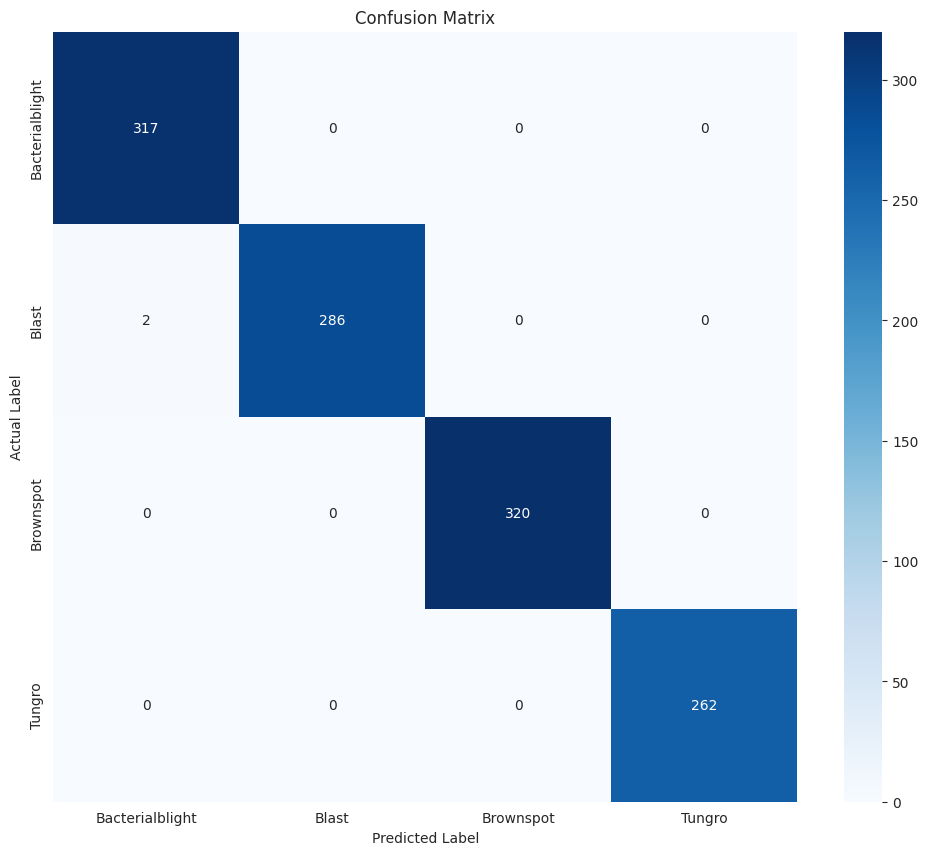

In [ ]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

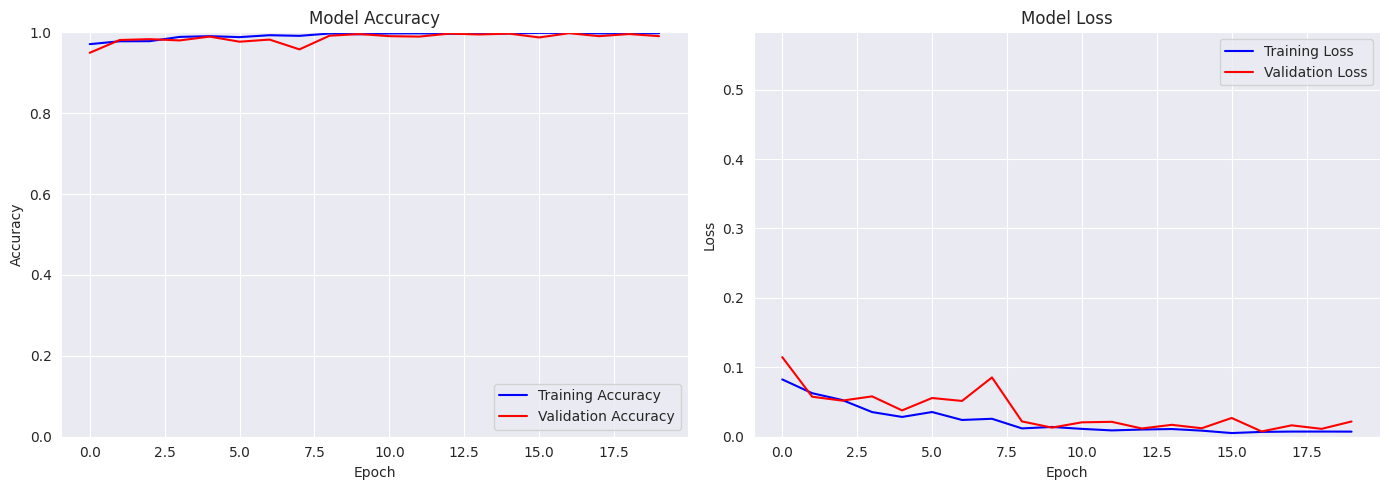

In [ ]:
if 'history_2' in locals():
    acc = history_2.history['accuracy']
    val_acc = history_2.history['val_accuracy']
    loss = history_2.history['loss']
    val_loss = history_2.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim([0, 1])

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.ylim([0, max(loss)+0.5])

    plt.tight_layout()
    plt.show()
else:
    print("Variabel 'history' tidak ditemukan. Pastikan Anda menyimpan output model.fit ke variabel 'history'.")

In [ ]:
shutil.copy("/content/model_padi_mobilenetv2.keras", "/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Model/Rice_MobileNetV2_fine-tuning.keras")

'/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Model/Rice_MobileNetV2_fine-tuning.keras'

In [ ]:
predict_image('/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Sample/3c4f2de5549f80.webp', model, class_names)
predict_image('/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Sample/brownspot.jpg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Sample/brown-spot-disease-rice-caused-260nw-2570506623.webp', model, class_names)
predict_image('/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Sample/penyakit-hawar-daun-bakteri.jpg', model, class_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted: Tungro (Confidence: 99.89%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Predicted: Brownspot (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
Predicted: Blast (Confidence: 99.61%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Predicted: Bacterialblight (Confidence: 100.00%)


('Bacterialblight', np.float32(0.99999785))

In [ ]:
model = tf.keras.models.load_model('/content/model_padi_mobilenetv2.keras')
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT] # Optimasi ukuran
tflite_model = converter.convert()

with open('/content/drive/MyDrive/DEEP_LEARNING/Rice Disease/Model/Rice_MobileNetV2_fine-tuning.tflite', 'wb') as f:
    f.write(tflite_model)

Saved artifact at '/tmp/tmpuz4hs627'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_4')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134433525729040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134433525735184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134433525735568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134433525729232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134433525737872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134433525734992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134433525743056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134433525739216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134433525735376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134433525733648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1344335257374